<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/02_image_classification_app_beans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌱 Application · Image classification: diagnosing bean diseases in Uganda

Beans are one of the most important foods in East Africa: cheap protein for millions of families, and an income for
smallholder farmers. Two diseases regularly destroy harvests: **angular leaf spot** (brown angular patches) and **bean
rust** (small rusty pustules). Spotting them early means treating early, but agricultural experts are few and far from
most fields.

The **Makerere University AI Lab** (Kampala, Uganda) and the national crop research institute photographed bean
leaves **with ordinary smartphones**, directly in farmers' fields, and labelled them. The same lab later co-organised
the famous Kaggle competition [Cassava Leaf Disease Classification](https://www.kaggle.com/competitions/cassava-leaf-disease-classification)
(2020) and Zindi challenges such as *Makerere Passion Fruit Disease Detection*. Crop disease diagnosis is a classic of
African AI competitions.

**Your mission:** classify a leaf photo as `angular_leaf_spot`, `bean_rust` or `healthy`. **Metric:** accuracy.

**The big idea of this notebook: transfer learning.** We only have ~1 000 photos. Instead of training a network from
zero (like in the Fashion-MNIST quest), we start from a network **pre-trained on ImageNet** (millions of photos). It
already knows edges, textures and shapes; we just teach it the last mile: what a sick bean leaf looks like.

| Step | Why |
|---|---|
| 1. Load & explore | check classes, balance, image quality |
| 2. Linear probe (frozen backbone) | the fastest strong baseline |
| 3. Fine-tuning with augmentation | adapt the whole network to leaves |
| 4. Test-time augmentation (TTA) | a free boost used in nearly every vision competition |
| 5. Error analysis & Grad-CAM | understand *what* the model looks at |
| 6. Submission | the competition deliverable |

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import io
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
import huggingface_hub
huggingface_hub.utils.logging.set_verbosity_error()   # hide download chatter from the model hub
huggingface_hub.utils.disable_progress_bars()

DEVICE = get_device()
quest("Diagnose bean diseases", chapter="Track 3 · Computer vision · Image classification", xp=250)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Diagnose bean diseases
   Track 3 · Computer vision · Image classification
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load and explore the data 📥

The dataset is hosted on Hugging Face (`AI-Lab-Makerere/beans`). Our helper `hf_parquet` downloads its Parquet
files once into `data/hf/` (~180 MB). The images are stored as bytes; we decode them with Pillow.

In [3]:
CLASSES = ["angular_leaf_spot", "bean_rust", "healthy"]
splits = {s: hf_parquet("AI-Lab-Makerere/beans", s) for s in ["train", "validation", "test"]}

def decode(df):
    return [Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in df["image"]]

images = {s: decode(df) for s, df in splits.items()}
labels = {s: df["labels"].to_numpy() for s, df in splits.items()}
for s in splits:
    counts = pd.Series(labels[s]).map(dict(enumerate(CLASSES))).value_counts().to_dict()
    print(f"{s:<10} {len(images[s]):>5} images · {counts}")
print("Image size:", images["train"][0].size)

train       1034 images · {'bean_rust': 348, 'angular_leaf_spot': 345, 'healthy': 341}
validation   133 images · {'bean_rust': 45, 'angular_leaf_spot': 44, 'healthy': 44}
test         128 images · {'angular_leaf_spot': 43, 'bean_rust': 43, 'healthy': 42}
Image size: (500, 500)


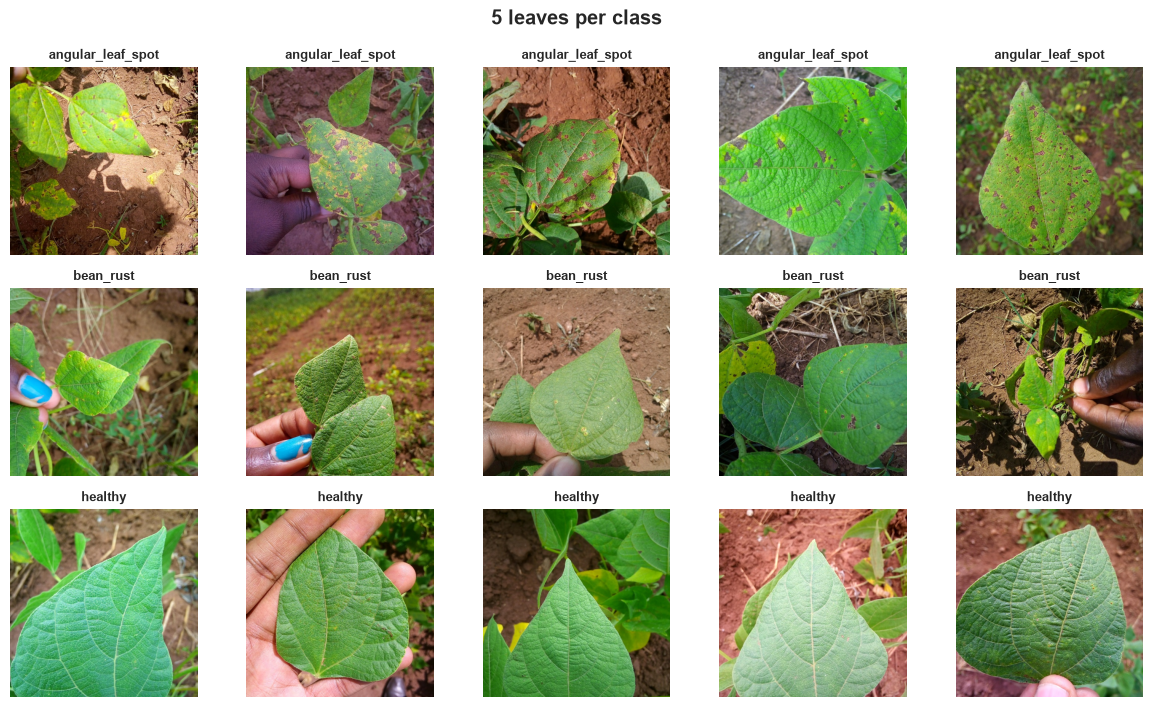

In [4]:
idx = [np.where(labels["train"] == c)[0][:5] for c in range(3)]
show_images([images["train"][i] for row in idx for i in row],
            titles=[CLASSES[c] for c, row in enumerate(idx) for _ in row], ncols=5, size=2.4,
            suptitle="5 leaves per class")

**Observations:** classes are balanced (≈ 1/3 each, so accuracy is a fair metric), photos are 500×500 with busy
backgrounds (soil, other leaves, hands): the model must learn to focus on the leaf. Rust looks like small dots, leaf
spot like larger brown patches.

## 2. Datasets, transforms and a pre-trained backbone 🧰

A pre-trained model expects images prepared **exactly as during its pre-training** (size, normalisation). `timm`
(PyTorch Image Models, ~1 000 architectures) gives us that configuration. We use **ConvNeXt-Nano**, a modern,
compact CNN (15 M parameters) that was pre-trained on ImageNet.

convnext_nano.in12k_ft_in1k: 15.0 M parameters · feature size 640 · mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


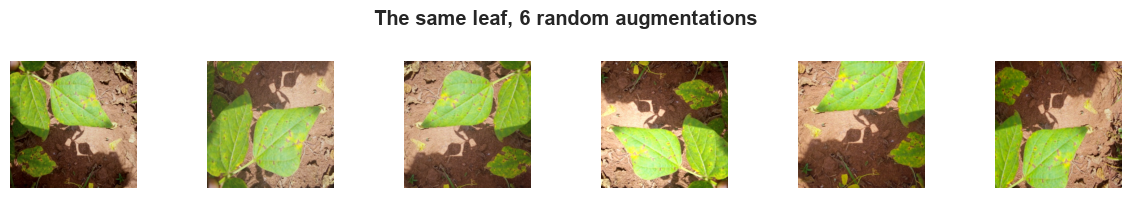

In [5]:
BACKBONE = "convnext_nano.in12k_ft_in1k"
IMG_SIZE = 224
probe = timm.create_model(BACKBONE, pretrained=True, num_classes=0)   # num_classes=0 → returns features, no head
cfg = timm.data.resolve_data_config({}, model=probe)
MEAN, STD = cfg["mean"], cfg["std"]
print(f"{BACKBONE}: {sum(p.numel() for p in probe.parameters()) / 1e6:.1f} M parameters · "
      f"feature size {probe.num_features} · mean={MEAN} std={STD}")

eval_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
train_tf = transforms.Compose([                     # augmentation: every epoch sees slightly different leaves
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])


class LeafDataset(Dataset):
    def __init__(self, imgs, ys, tf):
        self.imgs, self.ys, self.tf = imgs, ys, tf

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        return self.tf(self.imgs[i]), int(self.ys[i])


def loader(split, tf, shuffle=False, bs=32):
    return DataLoader(LeafDataset(images[split], labels[split], tf), batch_size=bs, shuffle=shuffle,
                      num_workers=NUM_WORKERS)

show_images([LeafDataset(images["train"], labels["train"], train_tf)[0][0] * torch.tensor(STD)[:, None, None]
             + torch.tensor(MEAN)[:, None, None] for _ in range(6)], ncols=6, size=2,
            suptitle="The same leaf, 6 random augmentations")

## 3. Baseline: the linear probe 🧱

We **freeze** the backbone, turn each image into a vector of 640 features, and train a simple logistic regression on
top. No GPU training needed, and it's a surprisingly strong baseline: it measures how useful ImageNet knowledge is
for our problem *before* any fine-tuning.

In [6]:
@torch.no_grad()
def extract_features(model, dl):
    model.eval().to(DEVICE)
    return torch.cat([model(x.to(DEVICE)).cpu() for x, _ in dl]).numpy()

from sklearn.linear_model import LogisticRegression
t0 = time.time()
F = {s: extract_features(probe, loader(s, eval_tf)) for s in ["train", "validation"]}
clf = LogisticRegression(max_iter=3000, C=0.5).fit(F["train"], labels["train"])
probe_acc = clf.score(F["validation"], labels["validation"])

lb = Leaderboard("beans", metric="val_accuracy")
lb.add("Random guess", 1 / 3)
lb.add("Linear probe (frozen ConvNeXt-Nano)", probe_acc)
print(f"(features + logistic regression in {time.time() - t0:.0f}s)")

📋 Random guess: val_accuracy = 0.33333
📋 Linear probe (frozen ConvNeXt-Nano): val_accuracy = 0.96992  👑 new best!
(features + logistic regression in 29s)


In [7]:
checkpoint("beans/probe", xp=40)

✅ Checkpoint · beans/probe (+40 XP)
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 4. Fine-tuning the whole network 🔥

Now we unfreeze everything and train end-to-end, with a few best practices:
- a **new classification head** with 3 outputs (`num_classes=3`),
- **AdamW** with a small learning rate (we don't want to destroy the pre-trained knowledge),
- a **cosine schedule**: the learning rate slowly decreases to almost 0,
- **label smoothing**: the target is "95% sure" instead of "100% sure", which makes models less over-confident,
- we keep the weights of the epoch with the **lowest validation loss** (with only 133 validation images, accuracy
  moves by steps of 0.75% and quickly hits 100%: the loss is a finer signal).

epoch 1 · train acc 0.794 · val loss 0.325 · val acc 1.000 · 92s  💾 best so far


epoch 2 · train acc 0.924 · val loss 0.323 · val acc 0.977 · 95s  💾 best so far


epoch 3 · train acc 0.972 · val loss 0.375 · val acc 0.970 · 83s


epoch 4 · train acc 0.979 · val loss 0.405 · val acc 0.940 · 114s


epoch 5 · train acc 0.989 · val loss 0.317 · val acc 0.985 · 60s  💾 best so far


epoch 6 · train acc 0.990 · val loss 0.312 · val acc 0.985 · 33s  💾 best so far


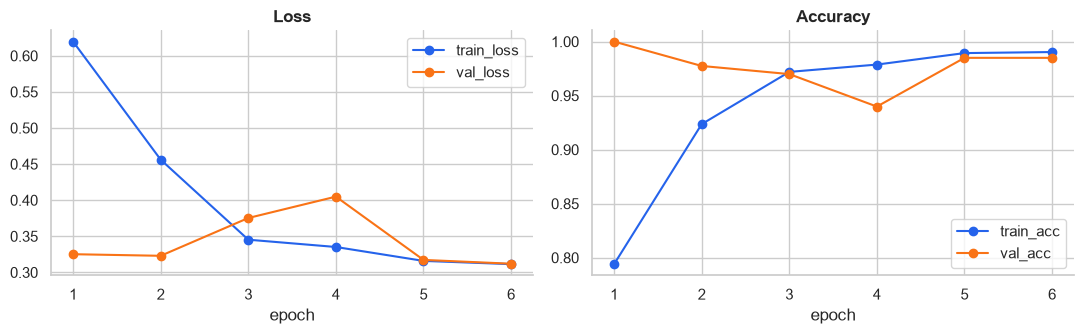

📋 Fine-tuned ConvNeXt-Nano: val_accuracy = 0.98496  👑 new best!


In [8]:
def run_epoch(model, dl, optimizer=None, scheduler=None, loss_fn=nn.CrossEntropyLoss(label_smoothing=0.1)):
    train = optimizer is not None
    model.train(train)
    total, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = loss_fn(logits, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step(); scheduler.step()
            total += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); n += len(y)
    return total / n, correct / n


seed_everything(SEED)
model = timm.create_model(BACKBONE, pretrained=True, num_classes=3).to(DEVICE)
EPOCHS = 6
train_dl, val_dl = loader("train", train_tf, shuffle=True), loader("validation", eval_tf)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-4, total_steps=EPOCHS * len(train_dl), pct_start=0.15)

history, best_loss, best_acc = [], float("inf"), 0.0
best_path = RUNS_DIR / "beans_convnext_nano.pt"
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(model, train_dl, optimizer, scheduler)
    va_loss, va_acc = run_epoch(model, val_dl)
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc, val_acc=va_acc))
    flag = ""
    if va_loss < best_loss:
        best_loss, best_acc, flag = va_loss, va_acc, "  💾 best so far"
        torch.save(model.state_dict(), best_path)
    print(f"epoch {epoch} · train acc {tr_acc:.3f} · val loss {va_loss:.3f} · val acc {va_acc:.3f} · {time.time() - t0:.0f}s{flag}")

h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
h.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[0], title="Loss")
h.plot(x="epoch", y=["train_acc", "val_acc"], marker="o", ax=axes[1], title="Accuracy")
plt.tight_layout(); plt.show()
model.load_state_dict(torch.load(best_path, map_location=DEVICE))
lb.add("Fine-tuned ConvNeXt-Nano", best_acc)

## 5. Test-time augmentation (TTA) 🪞

At prediction time, we show the model several versions of each image (original, flipped horizontally, flipped
vertically…) and **average** the probabilities. Each view gives a slightly different opinion; the average is more
reliable. It costs nothing in training, so competitors use it almost always.

In [9]:
@torch.no_grad()
def predict_proba(model, split, tta=False):
    model.eval()
    probs = []
    for x, _ in loader(split, eval_tf, bs=64):
        x = x.to(DEVICE)
        views = [x] + ([x.flip(3), x.flip(2), x.flip(2).flip(3)] if tta else [])
        probs.append(torch.stack([model(v).softmax(1) for v in views]).mean(0).cpu())
    return torch.cat(probs).numpy()

for tta in (False, True):
    p = predict_proba(model, "validation", tta=tta)
    print(f"TTA={tta!s:<5} → val accuracy {(p.argmax(1) == labels['validation']).mean():.3f}")
p_val_tta = predict_proba(model, "validation", tta=True)
lb.add("Fine-tuned + TTA (4 flips)", (p_val_tta.argmax(1) == labels["validation"]).mean())
lb.show()

TTA=False → val accuracy 0.985


TTA=True  → val accuracy 0.992


📋 Fine-tuned + TTA (4 flips): val_accuracy = 0.99248  👑 new best!


,,model,val_accuracy
rank,,,
1,🥇,Fine-tuned + TTA (4 flips),0.99248
2,🥈,Fine-tuned ConvNeXt-Nano,0.98496
3,🥉,Linear probe (frozen ConvNeXt-Nano),0.96992
4,,Random guess,0.33333


In [10]:
checkpoint("beans/finetune", xp=60)

✅ Checkpoint · beans/finetune (+60 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ░░░░░░░░░░░░░░░░░░░░░░░░ 100/300 XP


## 6. The moment of truth: the test set 🏁

We touched the validation set many times (to choose epochs, TTA…), and it is tiny, so its score is optimistic. The
**test set** was never used: it's our private leaderboard. Expect it to be a bit lower than validation: that gap is
exactly the "shake-up" of the playbook notebook.

🏁 Test accuracy: 0.961

                   precision    recall  f1-score   support

angular_leaf_spot      0.953     0.953     0.953        43
        bean_rust      0.932     0.953     0.943        43
          healthy      1.000     0.976     0.988        42

         accuracy                          0.961       128
        macro avg      0.962     0.961     0.961       128
     weighted avg      0.961     0.961     0.961       128



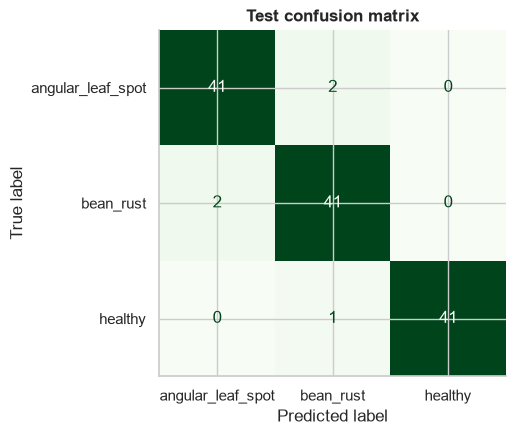

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

p_test = predict_proba(model, "test", tta=True)
pred_test = p_test.argmax(1)
print(f"🏁 Test accuracy: {(pred_test == labels['test']).mean():.3f}\n")
print(classification_report(labels["test"], pred_test, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay.from_predictions(labels["test"], pred_test, display_labels=CLASSES, cmap="Greens", colorbar=False)
plt.title("Test confusion matrix"); plt.show()

## 7. What is the model looking at? Grad-CAM 🔥

A good score is not enough: in agriculture or medicine, we want to know **why** the model decides. **Grad-CAM**
(2017) highlights the regions of the image that pushed the model towards its prediction: it weights the last feature
maps of the CNN by the gradient of the predicted class score.

If the heat map lights up the **lesions**, great. If it lights up the background or the farmer's hand holding the
leaf, the model may have learnt a **shortcut** (for example, if sick leaves were more often photographed in hand), and
it will fail in a new field. Look at the maps below with that critical eye.

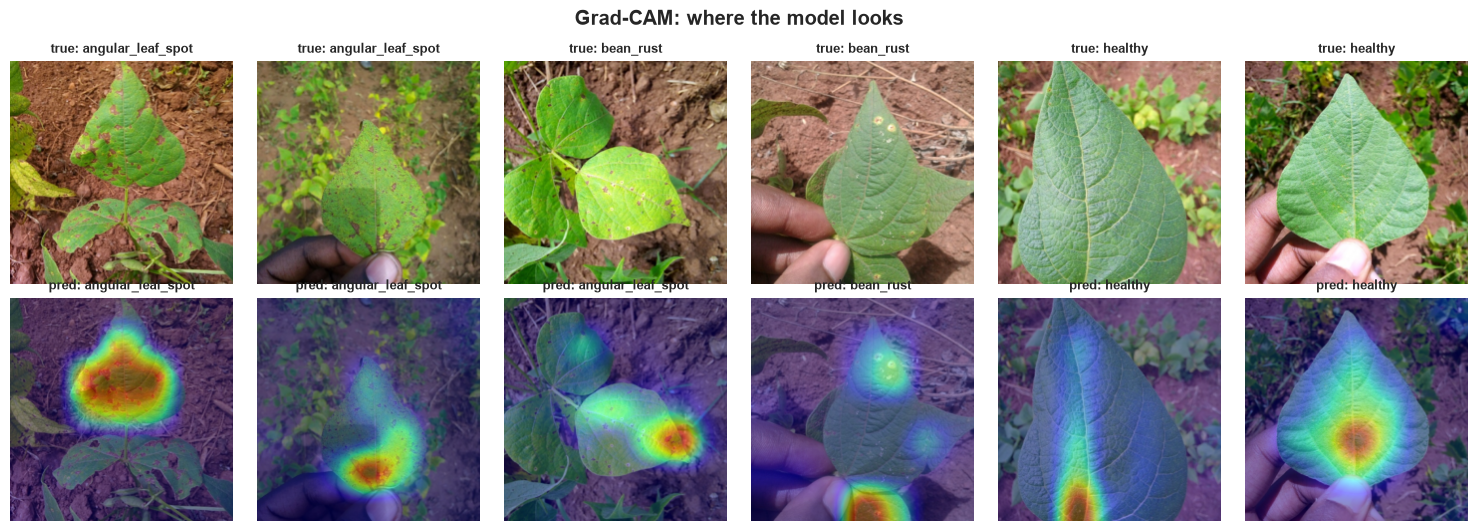

In [12]:
def grad_cam(model, img_tensor):
    """Grad-CAM for timm CNNs: weights the last feature maps by the gradient of the predicted class."""
    model.eval()
    x = img_tensor.unsqueeze(0).to(DEVICE)
    feats = model.forward_features(x)              # (1, C, h, w): the last feature maps
    feats.retain_grad()
    logits = model.forward_head(feats)
    cls = logits.argmax(1).item()
    model.zero_grad(); logits[0, cls].backward()
    weights = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * feats).sum(1))[0].detach().cpu()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.numpy(), cls


test_ds = LeafDataset(images["test"], labels["test"], eval_tf)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for k, i in enumerate([0, 1, 50, 51, 100, 101]):
    x, y = test_ds[i]
    cam, cls = grad_cam(model, x)
    img = np.asarray(eval_tf.transforms[1](eval_tf.transforms[0](images["test"][i])))
    axes[0, k].imshow(img); axes[0, k].set_title(f"true: {CLASSES[y]}", fontsize=9)
    axes[1, k].imshow(img); axes[1, k].imshow(np.array(Image.fromarray(np.uint8(cam * 255)).resize(img.shape[:2][::-1])),
                                              cmap="jet", alpha=0.45)
    axes[1, k].set_title(f"pred: {CLASSES[cls]}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Grad-CAM: where the model looks", fontweight="bold"); plt.tight_layout(); plt.show()

## 8. Submission 📤

Competition platforms expect one row per test image with the predicted label (or the probabilities, read the rules!).

🕵️ Fun fact: in this public dataset, the original file names contain the answer
(`angular_leaf_spot_test.0.jpg`…). That's a **leak**: in a real competition, organisers anonymise the ids. We do the
same in our submission.

In [13]:
submission = pd.DataFrame({
    "image_id": [f"test_{i:03d}" for i in range(len(pred_test))],
    "label": [CLASSES[k] for k in pred_test],
})
make_submission(submission, "beans_submission.csv")
submission.head()

📤 Submission saved: submissions/beans_submission.csv  (128 rows, columns=['image_id', 'label'])


,image_id,label
0,test_000,angular_leaf_spot
1,test_001,angular_leaf_spot
2,test_002,angular_leaf_spot
3,test_003,angular_leaf_spot
4,test_004,angular_leaf_spot


## 🏁 Mission accomplished

From 1 000 smartphone photos, transfer learning gives a model that diagnoses most leaves correctly, in a few minutes
on a laptop. That's why transfer learning is the default strategy in every vision competition.

### 🚀 Your turn (bonus XP)
1. Try another backbone from `timm.list_models("*efficientnet*", pretrained=True)` or a bigger ConvNeXt. Faster? Better?
2. Train at a higher resolution (`IMG_SIZE = 320`): lesions are tiny, more pixels may help.
3. Freeze the backbone for the first epoch, then unfreeze it (a classic "warm-up" trick).
4. Merge train + validation, retrain with the same settings, and predict the test set: more data, better model.
5. Real challenge: Kaggle's Cassava Leaf Disease Classification is still open for late submissions.

In [14]:
checkpoint("beans/complete", xp=150)
badge("Crop Doctor", "🌱")
progress()

✅ Checkpoint · beans/complete (+150 XP)
   ██████████████████░░░░░░ 250/300 XP
╔════════════════════════════════╗
║ 🌱  BADGE UNLOCKED: Crop Doctor ║
╚════════════════════════════════╝
🐣 Data Explorer
██████████████████░░░░░░ 250/300 XP
Checkpoints unlocked: 3
Badges: 🌱 Crop Doctor
